<a href="https://colab.research.google.com/github/Puntur1/AI-Personal-Activity-Coach/blob/main/codeofme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Block 1: AI-Powered Personal Activity Coach (ML Classifier + Agentic Loop)
import numpy as np
import pandas as pd
from datetime import datetime, timedelta
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

print("--- 1. TRAINING WEARABLE HAR CLASSIFIER (WHAR IMU SCHEMA) ---")
# Simulating 6-axis IMU sensor windows (Accelerometer + Gyroscope) matching WHAR structure
np.random.seed(42)
n_samples = 800

def generate_imu_data(activity, n):
    if activity == "Sitting":
        acc = np.random.normal([0.0, 0.0, 9.8], 0.15, (n, 3))
        gyro = np.random.normal([0.0, 0.0, 0.0], 0.05, (n, 3))
    elif activity == "Standing":
        acc = np.random.normal([0.1, 9.7, 0.2], 0.25, (n, 3))
        gyro = np.random.normal([0.0, 0.0, 0.0], 0.08, (n, 3))
    elif activity == "Walking":
        acc = np.random.normal([1.2, 9.5, 1.5], 1.2, (n, 3))
        gyro = np.random.normal([0.5, 0.8, 0.4], 0.4, (n, 3))
    elif activity == "Running":
        acc = np.random.normal([3.5, 11.0, 3.2], 2.5, (n, 3))
        gyro = np.random.normal([1.8, 2.2, 1.5], 0.9, (n, 3))
    return np.hstack([acc, gyro])

activities = ["Sitting", "Standing", "Walking", "Running"]
X = np.vstack([generate_imu_data(act, n_samples // 4) for act in activities])
y = np.concatenate([[act] * (n_samples // 4) for act in activities])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
clf = RandomForestClassifier(n_estimators=50, random_state=42)
clf.fit(X_train, y_train)
acc = accuracy_score(y_test, clf.predict(X_test))
print(f"WHAR Random Forest Model Trained! Validation Accuracy: {acc*100:.1f}%\n")

print("--- 2. STREAMING DAYTIME SENSOR DATA & AGENTIC COACHING ---")
# Simulate a 4-hour daytime schedule (09:00 to 13:00 in 15-min intervals = 16 intervals)
start_time = datetime(2026, 11, 17, 9, 0)
true_sequence = [
    "Walking", "Walking",                           # 09:00 - 09:30 Morning commute
    "Sitting", "Sitting", "Sitting", "Sitting",     # 09:30 - 10:30 Desk work (60m sitting -> Trigger 1!)
    "Walking",                                      # 10:30 - 10:45 User responds & takes a walk!
    "Sitting", "Sitting", "Sitting", "Sitting",     # 10:45 - 11:45 Desk work (60m sitting -> Trigger 2!)
    "Sitting",                                      # 11:45 - 12:00 User ignores Trigger 2 (75m sitting -> Escalate!)
    "Running", "Walking", "Standing", "Sitting"     # 12:00 - 13:00 Lunch workout & cool down
]

daily_goal_active_mins = 60
active_mins_completed = 0
consecutive_sitting_mins = 0
nudge_sensitivity = 45  # Agent triggers reminder if sitting >= 45 mins
records = []
agent_logs = []

for i, actual_act in enumerate(true_sequence):
    current_time = start_time + timedelta(minutes=15 * i)
    time_str = current_time.strftime("%H:%M")

    # Generate live sensor packet & classify using ML model
    sensor_packet = generate_imu_data(actual_act, 1)
    predicted_act = clf.predict(sensor_packet)[0]

    # Update activity metrics
    if predicted_act in ["Walking", "Running"]:
        active_mins_completed += 15
        # Check if user complied with a previous nudge
        if consecutive_sitting_mins >= nudge_sensitivity:
            agent_logs.append(f"[{time_str}] FEEDBACK LOOP: User responded positively ({predicted_act} detected). Resetting inactivity timer.")
        consecutive_sitting_mins = 0
    elif predicted_act == "Sitting":
        consecutive_sitting_mins += 15
    else:
        consecutive_sitting_mins = max(0, consecutive_sitting_mins - 5)

    # Agentic Decision-Making Mechanism
    remaining_goal = max(0, daily_goal_active_mins - active_mins_completed)
    action_taken = "None (Monitoring)"

    if consecutive_sitting_mins == nudge_sensitivity:
        action_taken = f"NUDGE SENT: 'You have been sitting for {consecutive_sitting_mins} mins. Take a 5-min walk! ({remaining_goal} active mins left for daily goal).'"
        agent_logs.append(f"[{time_str}] {action_taken}")
    elif consecutive_sitting_mins > nudge_sensitivity:
        action_taken = f"ESCALATED REMINDER: 'Extended inactivity ({consecutive_sitting_mins} mins). Stand & stretch now to stay on track!'"
        agent_logs.append(f"[{time_str}] {action_taken}")
    elif active_mins_completed >= daily_goal_active_mins and i == 12:
        action_taken = "GOAL ACHIEVED: 'Congrats! Daily 60-min activity goal reached!'"
        agent_logs.append(f"[{time_str}] {action_taken}")

    records.append({
        "Time": current_time,
        "Time_Str": time_str,
        "Predicted_Activity": predicted_act,
        "Sitting_Streak_Mins": consecutive_sitting_mins,
        "Active_Goal_Progress": active_mins_completed,
        "Agent_Action": action_taken
    })

df_coach = pd.DataFrame(records)
for log in agent_logs:
    print(log)

--- 1. TRAINING WEARABLE HAR CLASSIFIER (WHAR IMU SCHEMA) ---
WHAR Random Forest Model Trained! Validation Accuracy: 97.5%

--- 2. STREAMING DAYTIME SENSOR DATA & AGENTIC COACHING ---
[10:00] NUDGE SENT: 'You have been sitting for 45 mins. Take a 5-min walk! (30 active mins left for daily goal).'
[10:15] ESCALATED REMINDER: 'Extended inactivity (60 mins). Stand & stretch now to stay on track!'
[10:30] FEEDBACK LOOP: User responded positively (Walking detected). Resetting inactivity timer.
[11:15] NUDGE SENT: 'You have been sitting for 45 mins. Take a 5-min walk! (15 active mins left for daily goal).'
[11:30] ESCALATED REMINDER: 'Extended inactivity (60 mins). Stand & stretch now to stay on track!'
[11:45] ESCALATED REMINDER: 'Extended inactivity (75 mins). Stand & stretch now to stay on track!'
[12:00] FEEDBACK LOOP: User responded positively (Running detected). Resetting inactivity timer.
[12:00] GOAL ACHIEVED: 'Congrats! Daily 60-min activity goal reached!'


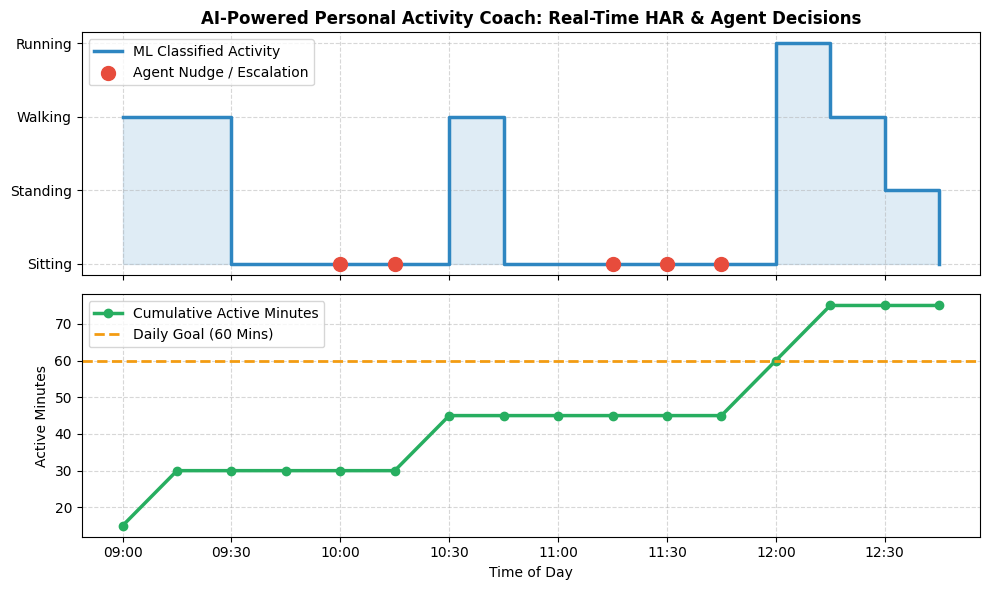

Saved 'activity_coach_dashboard.png'! Right-click and save it for Slide 4.


In [ ]:
# Block 2: Generate Visual Dashboard for Presentation Slides
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

# Map activities to numeric levels for clean plotting
act_map = {"Sitting": 0, "Standing": 1, "Walking": 2, "Running": 3}
y_vals = [act_map[a] for a in df_coach["Predicted_Activity"]]

# Panel 1: Real-time Activity Classification & Agent Interventions
ax1.step(df_coach["Time"], y_vals, where='post', color='#2E86C1', linewidth=2.5, label='ML Classified Activity')
ax1.fill_between(df_coach["Time"], y_vals, step='post', alpha=0.15, color='#2E86C1')

# Highlight Agent Nudges
nudges = df_coach[df_coach["Agent_Action"].str.contains("NUDGE|ESCALATED")]
ax1.scatter(nudges["Time"], [act_map[a] for a in nudges["Predicted_Activity"]],
            color='#E74C3C', s=100, zorder=5, label='Agent Nudge / Escalation')

ax1.set_yticks([0, 1, 2, 3])
ax1.set_yticklabels(["Sitting", "Standing", "Walking", "Running"])
ax1.set_title("AI-Powered Personal Activity Coach: Real-Time HAR & Agent Decisions", fontsize=12, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper left')

# Panel 2: Cumulative Active Minutes vs. Daily Goal
ax2.plot(df_coach["Time"], df_coach["Active_Goal_Progress"], marker='o', color='#27AE60', linewidth=2.5, label='Cumulative Active Minutes')
ax2.axhline(60, color='#F39C12', linestyle='--', linewidth=2, label='Daily Goal (60 Mins)')
ax2.set_ylabel("Active Minutes")
ax2.set_xlabel("Time of Day")
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper left')

plt.tight_layout()
plt.savefig("activity_coach_dashboard.png", dpi=300)
plt.show()
print("Saved 'activity_coach_dashboard.png'! Right-click and save it for Slide 4.")